# 03 — Traditional-feature similarity baseline

**Goal:** Retrieve similar songs using standardized FMA features and evaluate genre consistency. All retrieval logic comes from `scripts/baseline.py` rather than being duplicated here. Test tracks are queries; training tracks are candidates.

## 1. Colab / local repository setup
Set `REPO_URL` to your GitHub repository URL when using Colab. If the repository is already cloned, this cell uses it. For the latest changes, restart the runtime or run `git pull` manually.

In [1]:
from pathlib import Path
import os, sys, subprocess

REPO_NAME = "music-similarity-representation-learning"
REPO_URL = "https://github.com/samiyaalizaidi/music-similarity-representation-learning.git"

if Path('/content').exists():  # Colab
    repo = Path('/content') / REPO_NAME
    if not repo.exists():
        if 'YOUR_USERNAME' in REPO_URL:
            raise ValueError('Replace YOUR_USERNAME in REPO_URL with your GitHub username.')
        subprocess.run(['git', 'clone', REPO_URL, str(repo)], check=True)
    PROJECT_ROOT = repo
else:
    cwd = Path.cwd().resolve()
    PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / 'scripts' / 'baseline.py').is_file()), None)
    if PROJECT_ROOT is None:
        raise FileNotFoundError('Run the notebook inside your repository.')
os.chdir(PROJECT_ROOT)
print('Project root:', PROJECT_ROOT)
print('Baseline script:', (PROJECT_ROOT / 'scripts' / 'baseline.py').exists())

Project root: /content/music-similarity-representation-learning
Baseline script: True


## 2. Install and import dependencies

In [2]:
%pip -q install numpy pandas scikit-learn matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))
from baseline import load_data, build_index, retrieve, evaluate_genre_consistency

## 3. Load and validate processed data
No preprocessing is rerun. The files must already be committed under `data/processed/`.

In [10]:
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'

required = ['all.npz', 'metadata.csv']
missing = [name for name in required if not (PROCESSED_DIR / name).exists()]

if missing:
    raise FileNotFoundError(
        f'Missing processed files: {missing}. Pull the latest GitHub commit.'
    )

# FIX: Load the NPZ file with allow_pickle=True
with np.load(PROCESSED_DIR / 'all.npz', allow_pickle=True) as data:
    X = data['X']
    track_ids = data['track_ids']
    splits = data['split']

metadata = pd.read_csv(PROCESSED_DIR / 'metadata.csv', index_col=0)

print('Feature matrix:', X.shape)
print('Split counts:', pd.Series(splits).value_counts().to_dict())
print('Metadata columns:', list(metadata.columns))
print('Finite features:', bool(np.isfinite(X).all()))
display(metadata.head())

Feature matrix: (8000, 518)
Split counts: {'training': 6400, 'validation': 800, 'test': 800}
Metadata columns: ['split', 'genre', 'title', 'artist', 'tags']
Finite features: True


,split,genre,title,artist,tags
track_id,,,,,
2,training,Hip-Hop,Food,AWOL,[]
5,training,Hip-Hop,This World,AWOL,[]
10,training,Pop,Freeway,Kurt Vile,[]
140,training,Folk,Queen Of The Wires,Alec K. Redfearn & the Eyesores,[]
141,training,Folk,Ohio,Alec K. Redfearn & the Eyesores,[]


## 4. Build the baseline nearest-neighbor index
The candidate pool is restricted to training tracks. The evaluation queries come from the test split.

In [11]:
K = 5
model, candidate_indices = build_index(X, splits, k=K)
test_indices = np.flatnonzero(splits == 'test')
print('Training candidates:', len(candidate_indices))
print('Test queries:', len(test_indices))

Training candidates: 6400
Test queries: 800


## 5. Inspect three example queries

In [12]:
example_indices = test_indices[:3]
for idx in example_indices:
    qid = int(track_ids[idx])
    print('\nQUERY:', qid)
    display(metadata.loc[[qid], ['title', 'artist', 'genre']])
    results = retrieve(X, track_ids, splits, metadata, model, candidate_indices, int(idx), k=K)
    display(results[['rank', 'track_id', 'title', 'artist', 'genre', 'cosine_similarity', 'same_genre']].round(3))


QUERY: 182


,title,artist,genre
track_id,,,
182,Jules Lost His Jewels,Ariel Pink's Haunted Graffiti,Rock


,rank,track_id,title,artist,genre,cosine_similarity,same_genre
0,1,119086,Battle Hymn Of The Children,FortyOne,Experimental,0.443,False
1,2,131770,Babe,Microscopes,Pop,0.429,False
2,3,4522,Oceanus,High Places,Electronic,0.423,False
3,4,126221,Naram​-​Sin,Ø+yn + GMC,Experimental,0.423,False
4,5,58140,Travel On,John Bellows,Folk,0.417,False



QUERY: 704


,title,artist,genre
track_id,,,
704,Mano De Dios,Fósforo,International


,rank,track_id,title,artist,genre,cosine_similarity,same_genre
0,1,75929,Dark Kingdom,Tricky Diesel,Hip-Hop,0.594,False
1,2,141561,Please Listen,Yshwa,Hip-Hop,0.570,False
2,3,130709,Silly Guy,Jimmy & The Threats,Hip-Hop,0.561,False
3,4,69563,Good Time,The NSJ Crew,Hip-Hop,0.549,False
4,5,142567,Fell it,GOYMAMBA,International,0.530,True



QUERY: 705


,title,artist,genre
track_id,,,
705,Tio Cocodrilo,Fósforo,International


,rank,track_id,title,artist,genre,cosine_similarity,same_genre
0,1,85822,Nocturnia,Psychadelik Pedestrian,Electronic,0.601,False
1,2,53159,Spy VS Spy,Ras Amerlock,International,0.597,True
2,3,110265,Fact Is Remix (J. Glaze and Udachi Remix),Kellee Maize & J. Glaze & Udachi,Hip-Hop,0.593,False
3,4,75935,Still Balling,Tricky Diesel,Hip-Hop,0.575,False
4,5,69824,Lucky you (Digi G'Alessio remix remix),Infinite Livez,Hip-Hop,0.545,False


## 6. Evaluate genre consistency
Genre consistency is a **proxy**, not a human-judged measure of musical similarity. A cross-genre match is not automatically wrong.

In [13]:
metrics = [evaluate_genre_consistency(X, track_ids, splits, metadata, model, candidate_indices, k=k) for k in (5, 10)]
metrics_df = pd.DataFrame(metrics)
display(metrics_df.round(4))

,k,genre_consistency,cross_genre_rate,n_queries
0,5,0.3288,0.6712,800
1,10,0.3173,0.6828,800


## 7. Plot preliminary metrics

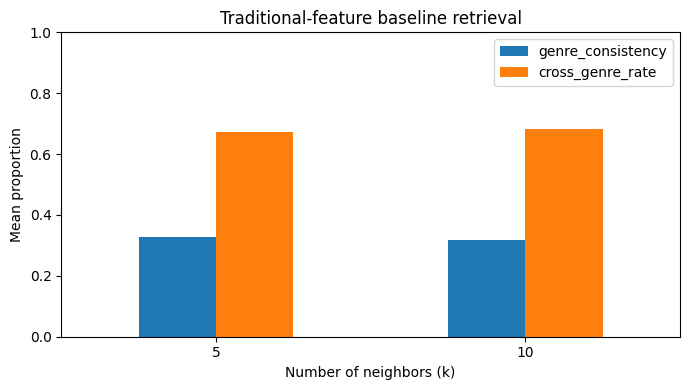

In [14]:
ax = metrics_df.plot(x='k', y=['genre_consistency', 'cross_genre_rate'], kind='bar', figsize=(7, 4), rot=0)
ax.set_xlabel('Number of neighbors (k)')
ax.set_ylabel('Mean proportion')
ax.set_ylim(0, 1)
ax.set_title('Traditional-feature baseline retrieval')
plt.tight_layout()
plt.show()

## 8. Save results for the milestone report

In [15]:
RESULTS_DIR = PROJECT_ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
metrics_df.to_csv(RESULTS_DIR / 'baseline_metrics.csv', index=False)
example_results = pd.concat([retrieve(X, track_ids, splits, metadata, model, candidate_indices, int(idx), k=K) for idx in example_indices], ignore_index=True)
example_results.to_csv(RESULTS_DIR / 'baseline_examples.csv', index=False)
print('Saved:', RESULTS_DIR / 'baseline_metrics.csv')
print('Saved:', RESULTS_DIR / 'baseline_examples.csv')

Saved: /content/music-similarity-representation-learning/results/baseline_metrics.csv
Saved: /content/music-similarity-representation-learning/results/baseline_examples.csv


## 9. Comparison with the autoencoder
Use the **same test queries, training candidate pool, cosine distance, and k values** with learned embeddings. Compare genre consistency and inspect cross-genre examples; do not treat genre agreement as ground-truth similarity.